In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

--- Parameters Loaded ---

--- Loading Data ---
   > 1/6 Generating Missingness Indicators...
   > 2/6 Imputing Missing Values...
   > 3/6 Applying Log Transformation...
   > 4/6 Engineering Histogram Totals...
   > 5/6 Engineering Cluster Distances (K-Means)...
   > 6/6 Dropping Highly Correlated Features...
   > Final Data Shape: (60000, 142) (Should be approx 142 features)

--- Training Final Stacking Ensemble ---


invalid value encountered in greater


Stacking Ensemble Trained.
--- Generating Submission ---
Done. 'submission_final.csv' created.

--- Generating SHAP Plot ---


The figure layout has changed to tight


SHAP Plot Saved.


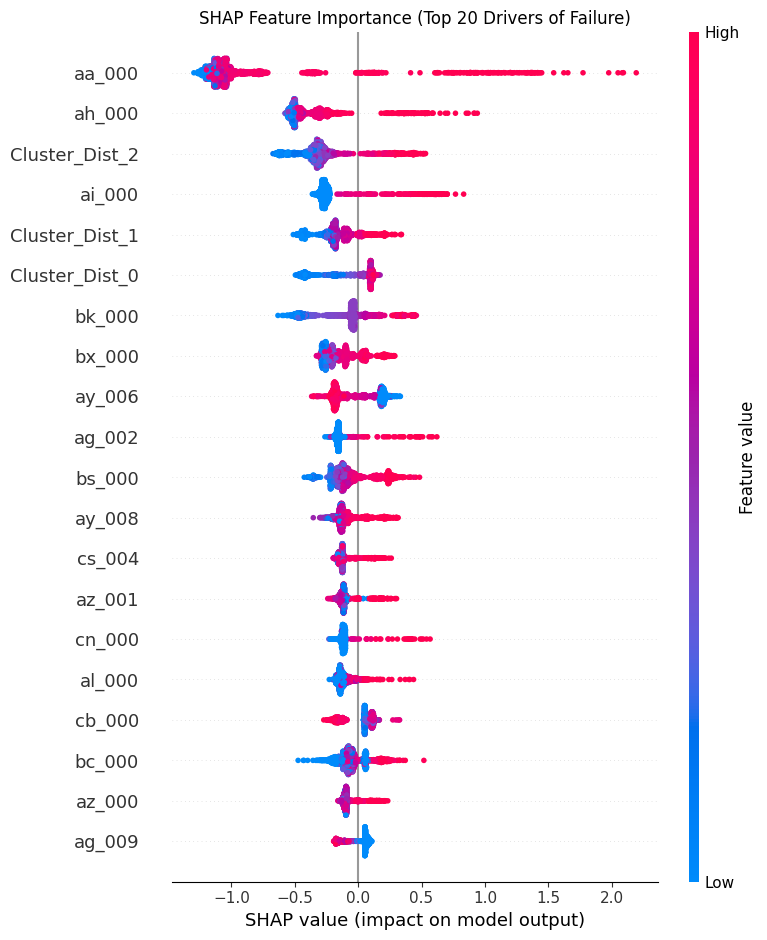

In [1]:
# ================================
# FINAL MACHINE LEARNING PIPELINE 
# ===============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans

# 1. FIXED SEEDS
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 2. HARDCODED "BEST PARAMETERS" (FROM Optuna based Hyper-parameter TUNING)
# -----------------------------------------------------------------------------
# LINEAR Model: Ridge
best_ridge_params = {
    'alpha': 1.05, 
    'class_weight': 'balanced',
    'max_iter': 5000,
    'random_state': RANDOM_STATE
}

best_cat_params = {
    'n_estimators': 963,
    'learning_rate': 0.01812158421513191,
    'depth': 4,
    'l2_leaf_reg': 9.7112131334515,
    'random_strength': 1.4561258911945636,
    'bagging_temperature': 0.9623859192146741,
    'border_count': 34,
    'auto_class_weights': 'Balanced',
    'verbose': 0,
    'allow_writing_files': False,
    'random_seed': RANDOM_STATE,
    'task_type': 'CPU' 
}

print("--- Parameters Loaded ---")

# 3. DATA LOADING
# -----------------------------------------------------------------------------
print("\n--- Loading Data ---")
X_train = pd.read_csv('/kaggle/input/ppcu-data-mining-and-machine-learning-2025/X_train.csv', na_values='na')
y_train = pd.read_csv('/kaggle/input/ppcu-data-mining-and-machine-learning-2025/y_train.csv', index_col='Id')
X_test_raw = pd.read_csv('/kaggle/input/ppcu-data-mining-and-machine-learning-2025/X_test.csv', na_values='na')

y_labels = y_train['Prediction'].str.strip().map({'neg': 0, 'pos': 1})

# -----------------------------------------------------------------------------
# 4.  PRE-PROCESSING PIPELINE
# -----------------------------------------------------------------------------

# STEP A: MISSING INDICATORS 
# We  identify which columns were 'missing' in Train, and create flags for them in both Train and Test
print("   > 1/6 Generating Missingness Indicators...")
cols_missing = [c for c in X_train.columns if X_train[c].isnull().mean() > 0.05]
# Train
X_train_missing = X_train[cols_missing].isnull().astype(int).add_suffix('_is_missing')
# Test
X_test_missing = X_test_raw[cols_missing].isnull().astype(int).add_suffix('_is_missing')

# STEP B: IMPUTATION (Median)
print("   > 2/6 Imputing Missing Values...")
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test_imp = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)

# STEP C: LOG TRANSFORMATION
print("   > 3/6 Applying Log Transformation...")
X_train_log = np.log1p(X_train_imp)
X_test_log = np.log1p(X_test_imp)

# STEP D: HISTOGRAM AGGREGATION
print("   > 4/6 Engineering Histogram Totals...")
def create_histogram_sums(df):
    df_eng = df.copy()
    prefixes = ['ag', 'ay', 'az', 'ba', 'cn', 'cs', 'ee']
    for prefix in prefixes:
        cols = [c for c in df.columns if c.startswith(prefix + '_')]
        if cols:
            df_eng[f'{prefix}_total'] = df[cols].sum(axis=1)
    return df_eng

X_train_eng = create_histogram_sums(X_train_log)
X_test_eng = create_histogram_sums(X_test_log)

# STEP E: MERGE & SCALE FOR K-MEANS
# We need to concatenate the Missing Flags back before Clustering
X_train_full = pd.concat([X_train_eng, X_train_missing], axis=1)
X_test_full = pd.concat([X_test_eng, X_test_missing], axis=1)

print("   > 5/6 Engineering Cluster Distances (K-Means)...")
# Scale first (Required for K-Means)
scaler_km = StandardScaler()
X_train_sc = scaler_km.fit_transform(X_train_full)
X_test_sc = scaler_km.transform(X_test_full)

kmeans = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_train_sc)

def add_cluster_features(X_data, X_sc):
    dist = kmeans.transform(X_sc)
    df = X_data.copy()
    for i in range(5):
        df[f'Cluster_Dist_{i}'] = dist[:, i]
    return df

X_train_w_clusters = add_cluster_features(X_train_full, X_train_sc)
X_test_w_clusters = add_cluster_features(X_test_full, X_test_sc)

# STEP F: CORRELATION FILTERING (Reducing Features)
print("   > 6/6 Dropping Highly Correlated Features...")
corr_matrix = X_train_w_clusters.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]

X_train_final = X_train_w_clusters.drop(columns=to_drop)
X_test_final = X_test_w_clusters.drop(columns=to_drop)

print(f"   > Final Data Shape: {X_train_final.shape} (Should be approx 142 features)")

# -----------------------------------------------------------------------------
# 5. MODEL TRAINING (STACKING)
# -----------------------------------------------------------------------------
print("\n--- Training Final Stacking Ensemble ---")

# Base Learners
ridge_model = RidgeClassifier(**best_ridge_params) # Linear
cat_model = CatBoostClassifier(**best_cat_params) # Non-Linear

estimators = [
    ('ridge', Pipeline([('scaler', StandardScaler()), ('model', ridge_model)])),
    ('cat', Pipeline([('scaler', StandardScaler()), ('model', cat_model)]))
]

# Meta-Learner Logistic regression decides between Linear and Non-Linear results
meta_model = LogisticRegression(class_weight='balanced', solver='liblinear', max_iter=5000, random_state=RANDOM_STATE)

stack = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_model,
    cv=5,
    n_jobs=-1
)

stack.fit(X_train_final, y_labels)
print("Stacking Ensemble Trained.")

# -----------------------------------------------------------------------------
# 6. SUBMISSION GENERATION
# -----------------------------------------------------------------------------
print("--- Generating Submission ---")
test_probs = stack.predict_proba(X_test_final)[:, 1]

FINAL_THRESHOLD = 0.65 
final_preds = (test_probs >= FINAL_THRESHOLD).astype(int)
final_labels = pd.Series(final_preds).map({0: 'neg', 1: 'pos'})

sub = pd.DataFrame({'Id': pd.read_csv('/kaggle/input/ppcu-data-mining-and-machine-learning-2025/X_test.csv').index, 'Prediction': final_labels})
sub.to_csv('submission_final.csv', index=False)
print("Done. 'submission_final.csv' created.")

# -----------------------------------------------------------------------------
# 7. SHAP INTERPRETATION (INTEGRATED)
# -----------------------------------------------------------------------------
print("\n--- Generating SHAP Plot ---")
# We retrain a standalone CatBoost on the FINAL PROCESSED DATA to avoid Pipeline issues
interpretable_model = CatBoostClassifier(**best_cat_params)
interpretable_model.fit(X_train_final, y_labels, verbose=0)

explainer = shap.TreeExplainer(interpretable_model)
X_sample = X_train_final.iloc[:2000] # Sample for speed
shap_values = explainer.shap_values(X_sample)

plt.figure(figsize=(12, 10))
shap.summary_plot(shap_values, X_sample, show=False, max_display=20)
plt.title("SHAP Feature Importance (Top 20 Drivers of Failure)")
plt.tight_layout()
plt.savefig('shap_summary_plot.png')
print("SHAP Plot Saved.")

Generating Advanced Evaluation Plots (CV Predictions)...


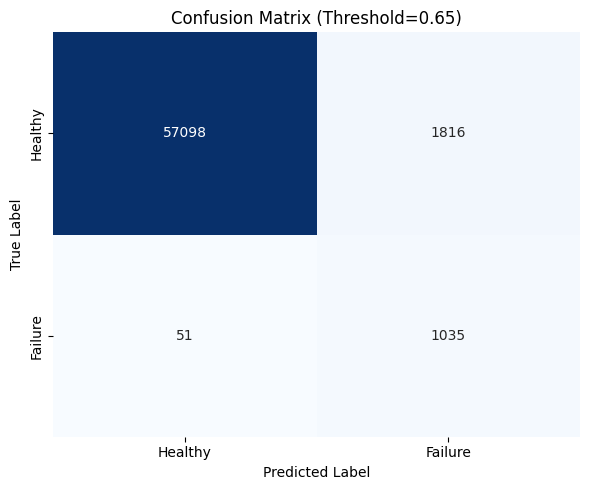

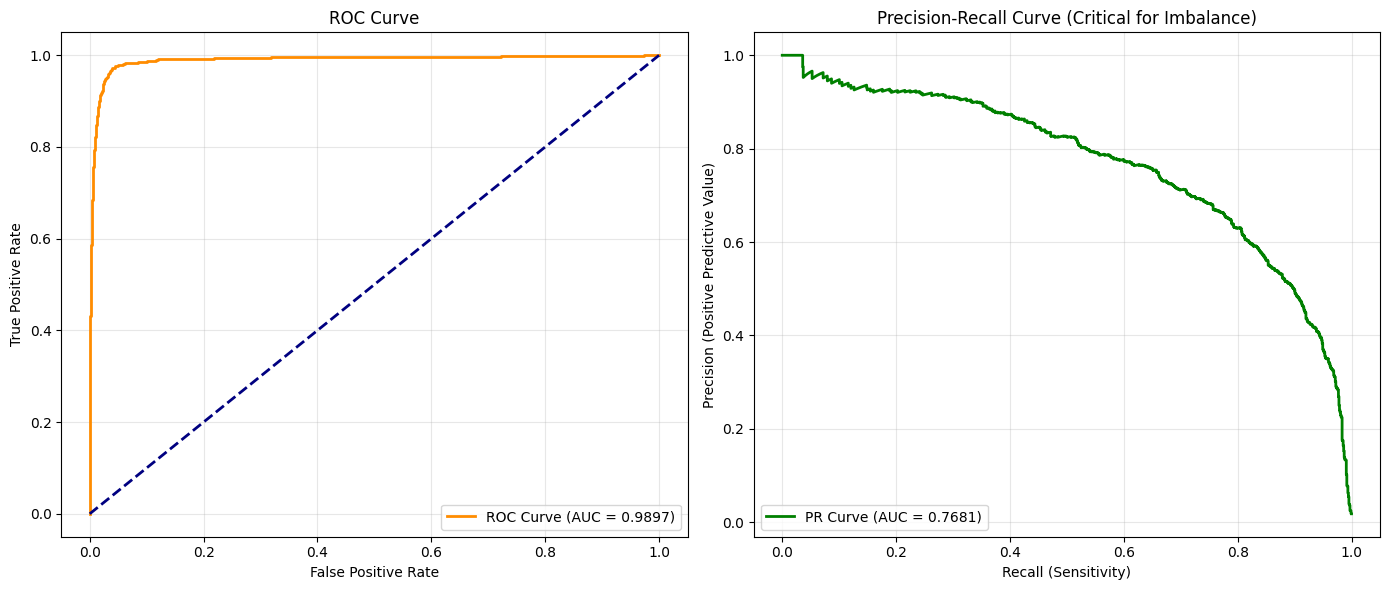

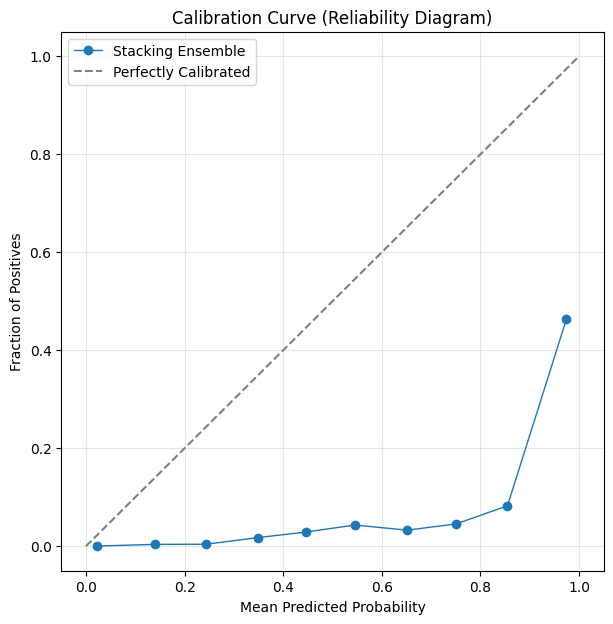

Plots Saved: fig7_confusion_matrix.png, fig8_evaluation_curves.png, fig9_calibration.png


In [3]:
     # ============================================
#  EVALUATION PLOTS (ROC, PR, CALIBRATION)
# =================================================
import matplotlib.pyplot as plt
import seaborn as sns  
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, 
                             roc_curve, auc, precision_recall_curve, average_precision_score)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import cross_val_predict


FINAL_THRESHOLD = 0.65 

print("Generating Advanced Evaluation Plots (CV Predictions)...")

# 1. Get Out-of-Fold Probabilities (Honest Validation)
# This simulates how the model performs on unseen data

y_probas = cross_val_predict(stack, X_train_final, y_labels, cv=5, method='predict_proba', n_jobs=-1)[:, 1]

# 2. PLOT 1: CONFUSION MATRIX (At Final Threshold 0.65)
final_preds_cv = (y_probas >= FINAL_THRESHOLD).astype(int)
cm = confusion_matrix(y_labels, final_preds_cv)

plt.figure(figsize=(6, 5))
# Plot raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Healthy', 'Failure'], yticklabels=['Healthy', 'Failure'])
plt.title(f'Confusion Matrix (Threshold={FINAL_THRESHOLD})')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('fig7_confusion_matrix.png')
plt.show()

# 3. PLOT 2: ROC and PRECISION-RECALL CURVES (Side by Side)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ROC Curve
fpr, tpr, _ = roc_curve(y_labels, y_probas)
roc_auc = auc(fpr, tpr)
ax1.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
ax1.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve')
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_labels, y_probas)
pr_auc = average_precision_score(y_labels, y_probas)
ax2.plot(recall, precision, color='green', lw=2, label=f'PR Curve (AUC = {pr_auc:.4f})')
ax2.set_xlabel('Recall (Sensitivity)')
ax2.set_ylabel('Precision (Positive Predictive Value)')
ax2.set_title('Precision-Recall Curve (Critical for Imbalance)')
ax2.legend(loc="lower left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig8_evaluation_curves.png')
plt.show()

# 4. PLOT 3: CALIBRATION CURVE
# Checks if the probabilities are realistic
prob_true, prob_pred = calibration_curve(y_labels, y_probas, n_bins=10)

plt.figure(figsize=(7, 7))
plt.plot(prob_pred, prob_true, marker='o', linewidth=1, label='Stacking Ensemble')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve (Reliability Diagram)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('fig9_calibration.png')
plt.show()

print("Plots Saved: fig7_confusion_matrix.png, fig8_evaluation_curves.png, fig9_calibration.png")

Generating 'Proof of Necessity' Statistics...
   > Getting Ridge Baseline predictions...
   > Getting CatBoost predictions...

=== THE PROOF OF BLACKBOX NECESSITY ===
Total Actual Failures: 1086
Failures caught by Linear Model (Ridge): [0 0 0 ... 0 0 0]
----------------------------------------
PROOF: Failures MISSED by Linear but CAUGHT by CatBoost: 11
       (These 11 trucks would have crashed if we stuck to Whitebox)
----------------------------------------
Net Gain from Non-Linearity: +-12 Failures Detected


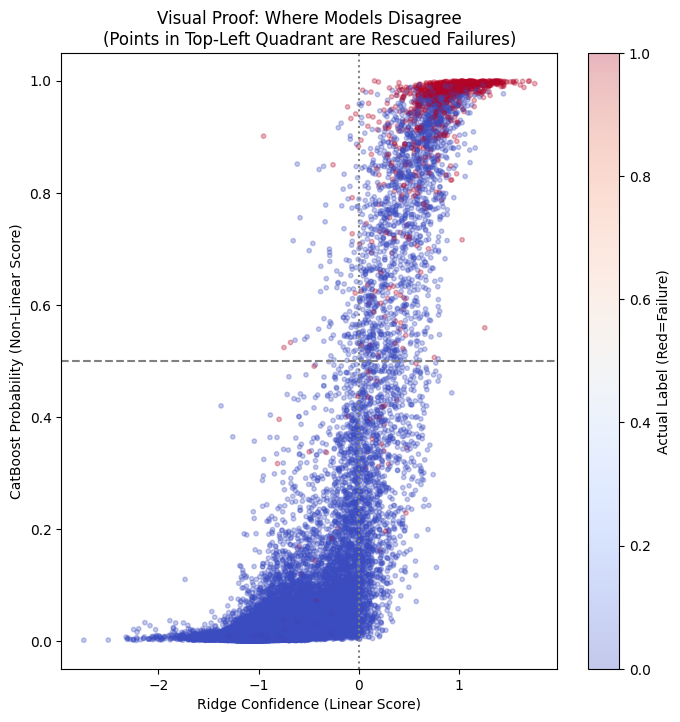

In [4]:
# =====================================================================
# THE NECESSITY PROOF THAT NON LINEAR MODELS LIKE CATBOOST IS REQUIRED
# =====================================================================
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

print("'Proof of Necessity' Statistics...")

# 1. Get Independent Predictions (Cross-Validated to be fair)
# We need to see what each model thinks ON ITS OWN
# estimators_[0] is Ridge, estimators_[1] is CatBoost
ridge_pipeline = stack.estimators_[0]
cat_pipeline = stack.estimators_[1]

# We use cross_val_predict to get 'clean' predictions for the whole train set
print("   > Getting Ridge Baseline predictions...")
y_pred_ridge = cross_val_predict(ridge_pipeline, X_train_final, y_labels, cv=5, method='predict')

print("   > Getting CatBoost predictions...")
y_pred_cat = cross_val_predict(cat_pipeline, X_train_final, y_labels, cv=5, method='predict')

# 2. Calculate the "Rescue Count"
# A "Rescue" is when: Ridge said "Healthy" (False Negative) BUT CatBoost said "Failure" (True Positive)
rescued_indices = (y_pred_ridge == 0) & (y_pred_cat == 1) & (y_labels == 1)
rescue_count = rescued_indices.sum()

# 3. Calculate the "Corruption Count" (Just to be fair/scientific)
# Did CatBoost break things Ridge got right?
# Ridge said "Failure" (True Positive) BUT CatBoost said "Healthy" (False Negative)
corrupted_indices = (y_pred_ridge == 1) & (y_pred_cat == 0) & (y_labels == 1)
corrupt_count = corrupted_indices.sum()

print("\n=== THE PROOF OF BLACKBOX NECESSITY ===")
print(f"Total Actual Failures: {y_labels.sum()}")
print(f"Failures caught by Linear Model (Ridge): {(y_pred_ridge == 1) & (y_labels == 1).sum()}")
print("-" * 40)
print(f"PROOF: Failures MISSED by Linear but CAUGHT by CatBoost: {rescue_count}")
print(f"       (These {rescue_count} trucks would have crashed if we stuck to Whitebox)")
print("-" * 40)
print(f"Net Gain from Non-Linearity: +{rescue_count - corrupt_count} Failures Detected")

# 4. Visual Proof (Disagreement Plot)
# Scatter plot of Probabilities. If they fall on diagonal, they are the same. 
# Deviation from diagonal = Non-Linearity at work.
y_prob_ridge = cross_val_predict(ridge_pipeline, X_train_final, y_labels, cv=5, method='decision_function')
y_prob_cat = cross_val_predict(cat_pipeline, X_train_final, y_labels, cv=5, method='predict_proba')[:, 1]

plt.figure(figsize=(8, 8))
plt.scatter(y_prob_ridge, y_prob_cat, c=y_labels, cmap='coolwarm', alpha=0.3, s=10)
plt.axhline(0.5, color='gray', linestyle='--', label='CatBoost Decision Boundary')
plt.axvline(0, color='gray', linestyle=':', label='Ridge Decision Boundary')
plt.xlabel("Ridge Confidence (Linear Score)")
plt.ylabel("CatBoost Probability (Non-Linear Score)")
plt.title("Visual Proof: Where Models Disagree\n(Points in Top-Left Quadrant are Rescued Failures)")
plt.colorbar(label="Actual Label (Red=Failure)")
plt.savefig('proof_of_necessity.png')
plt.show()